# Roteiro 11 - SVM

Este é o roteiro da décima segunda aula de laboratório da disciplina de Inteligência Artificial ministrada em 2024-2025 na UFMT.

O objetivo é desenvolver classificadores com SVM - Support Vector Machine usando os dados dos roteiros anteriores (8, 9 e 10).

O documento está organizado da seguinte forma:

- SVM linear
- SVM não-linear
- SVM não-linear para classificação de imagens
___________________________________________
Autor: raoni.teixeira@ufmt.br

# 1. SVM Linear

Considere novamente o conjunto de dados de diagnóstico médico do [Roteiro 8](https://colab.research.google.com/drive/1uqhF6cgDsQEfyKaui0MyJN_Qbyoi1Yhv?usp=sharing),  que  classifica pacientes como saudáveis ou doentes levando em conta duas variáveis reais obtidas de exames: `exame_1` e `exame_2`.

## Baixando Dados

In [ ]:
!gdown '1Zp5jwkCX-jD53PMCjX09pG_KeQ8mWbRh'

Downloading...
From: https://drive.google.com/uc?id=1Zp5jwkCX-jD53PMCjX09pG_KeQ8mWbRh
To: /content/data1.txt
100% 3.77k/3.77k [00:00<00:00, 13.8MB/s]


## Carregando pacotes

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn import svm
from sklearn.datasets import make_blobs

## Visualizando dados

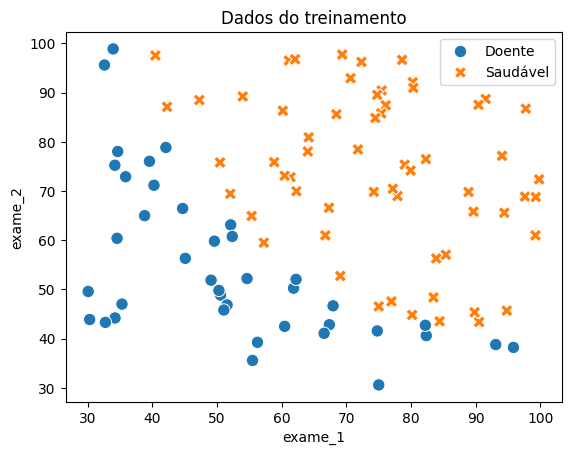

In [ ]:
df = pd.read_csv('data1.txt', sep=',', header=None)
df.columns = ['exame_1', 'exame_2', 'classe']
ax = sns.scatterplot(x='exame_1', y='exame_2', hue='classe', data=df, style='classe', s=80)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:], ['Doente', 'Saudável'])
plt.title('Dados do treinamento')
plt.show(ax)

## Treinando o modelo

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


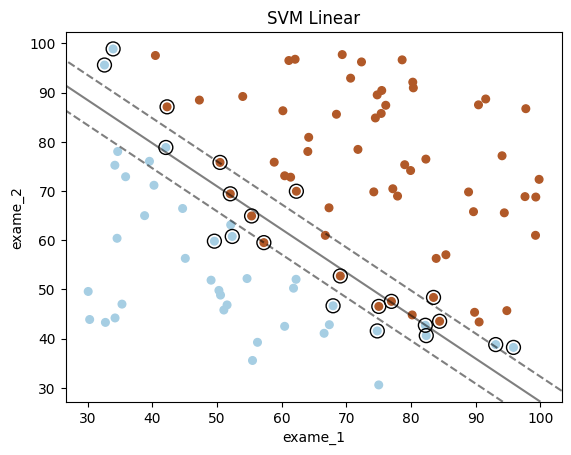

In [ ]:
X = df[['exame_1', 'exame_2']].values
y = np.array(df.classe.values).reshape(-1,1)

# Treinar o SVM linear
clf = svm.SVC(kernel='linear', C=1000)
clf.fit(X, y)

# Plotar os dados
plt.scatter(X[:, 0], X[:, 1], c=y, s=30, cmap=plt.cm.Paired)

# Plotar o hiperplano de decisão
ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

# Criar grid para avaliar o modelo
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
Z = clf.decision_function(xy).reshape(XX.shape)

# Plotar hiperplano e margens
ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.5,
           linestyles=['--', '-', '--'])

# Plotar vetores de suporte
ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=100,
           linewidth=1, facecolors='none', edgecolors='k')

plt.title('SVM Linear')
plt.xlabel('exame_1')
plt.ylabel('exame_2')
plt.show()

# SVM não-linear

Novamente, vamos considerar os dados do Roteiro 8. Os dados agora **não** são **linearmente separáveis**: não possível separar as classes com uma reta.

## Baixando Dados

In [ ]:
!gdown 1LOriAr0XtwpD5HWQ9ZgKRygrGWruiDf1

Downloading...
From: https://drive.google.com/uc?id=1LOriAr0XtwpD5HWQ9ZgKRygrGWruiDf1
To: /content/data2.txt
100% 2.23k/2.23k [00:00<00:00, 7.27MB/s]


## Visualizando os Dados

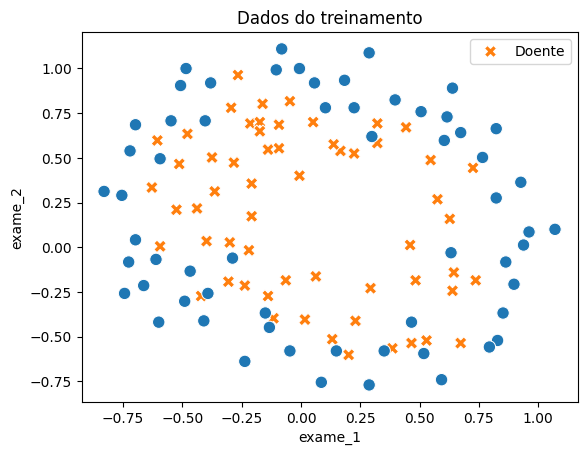

In [ ]:
df = pd.read_csv('data2.txt', sep=',', header=None)
df.columns = ['exame_1', 'exame_2', 'classe']
ax = sns.scatterplot(x='exame_1', y='exame_2', hue='classe', data=df, style='classe', s=80)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:], ['Doente', 'Saudável'])
plt.title('Dados do treinamento')
plt.show(ax)

## Treinando o modelo

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


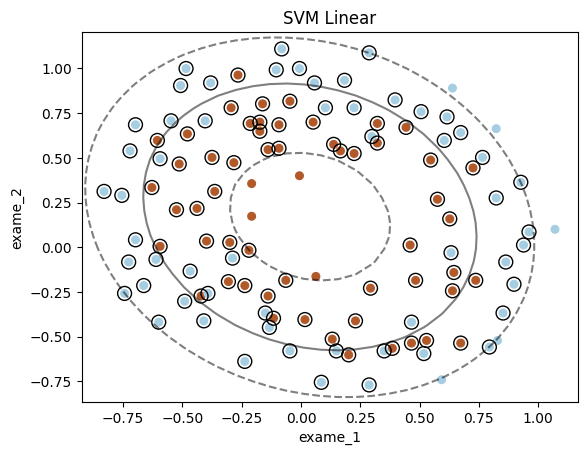

In [ ]:
X = df[['exame_1', 'exame_2']].values
y = np.array(df.classe.values).reshape(-1,1)

# Treinar o SVM linear
clf = svm.SVC(kernel='rbf', C=10, gamma=0.1)
clf.fit(X, y)

# Plotar os dados
plt.scatter(X[:, 0], X[:, 1], c=y, s=30, cmap=plt.cm.Paired)

# Plotar o hiperplano de decisão
ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

# Criar grid para avaliar o modelo
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
Z = clf.decision_function(xy).reshape(XX.shape)

# Plotar hiperplano e margens
ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.5,
           linestyles=['--', '-', '--'])

# Plotar vetores de suporte
ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=100,
           linewidth=1, facecolors='none', edgecolors='k')

plt.title('SVM Linear')
plt.xlabel('exame_1')
plt.ylabel('exame_2')
plt.show()

Neste exemplo, há mais **vetores de suporte** (pontos circulados) que no caso linear.

O SVM não-linear com kernel RBF mapeia os dados para um espaço de dimensão infinita, permitindo modelar separações complexas e altamente não lineares.

Como resultado, mais pontos se tornam *importantes* para definir a fronteira — ou seja, aumentam os vetores de suporte.

No SVM linear, a fronteira é uma reta, e apenas os dados mais próximos dela (as extremidades das classes) são relevantes.

Já com o RBF, a fronteira pode se curvar para acompanhar a distribuição real dos dados. Cada parte dessa curva depende de pontos próximos para manter seu formato.

Assim, mais dados passam a ser essenciais para definir a fronteira, tornando-se vetores de suporte.

# SVM não-linear (classificação de imagens)



Nesta parte da atividade, vamos utilizar  o conjunto de dados utilizado nos Roteiros 10 e 11 que corresponde a uma pequena parte da base MNIST de dı́gitos manuscritos (arquivo mnistdata.mat.).

A amostra considerada contém $5.000$ imagens de tamanho 20×20, normalizadas no intervalo [0−1].



## Baixando dados

In [ ]:
!gdown 1zyLpE4VpOd32vVkVBzH_Xy1V4u7rXMJz


Downloading...
From (original): https://drive.google.com/uc?id=1zyLpE4VpOd32vVkVBzH_Xy1V4u7rXMJz
From (redirected): https://drive.google.com/uc?id=1zyLpE4VpOd32vVkVBzH_Xy1V4u7rXMJz&confirm=t&uuid=99ca3e1f-377a-46dd-ad51-22605e63979e
To: /content/mnistdata.mat
100% 7.51M/7.51M [00:00<00:00, 30.6MB/s]


In [ ]:
from scipy.io import loadmat
from sklearn import datasets, svm, metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
def load_data():
    data = loadmat("mnistdata.mat")
    X = data["X"]
    y = data["y"].flatten()
    return X, y

print("Carregando dados...")
X, y = load_data()
y[y == 10] = 0

Carregando dados...


## Visualizando os dados

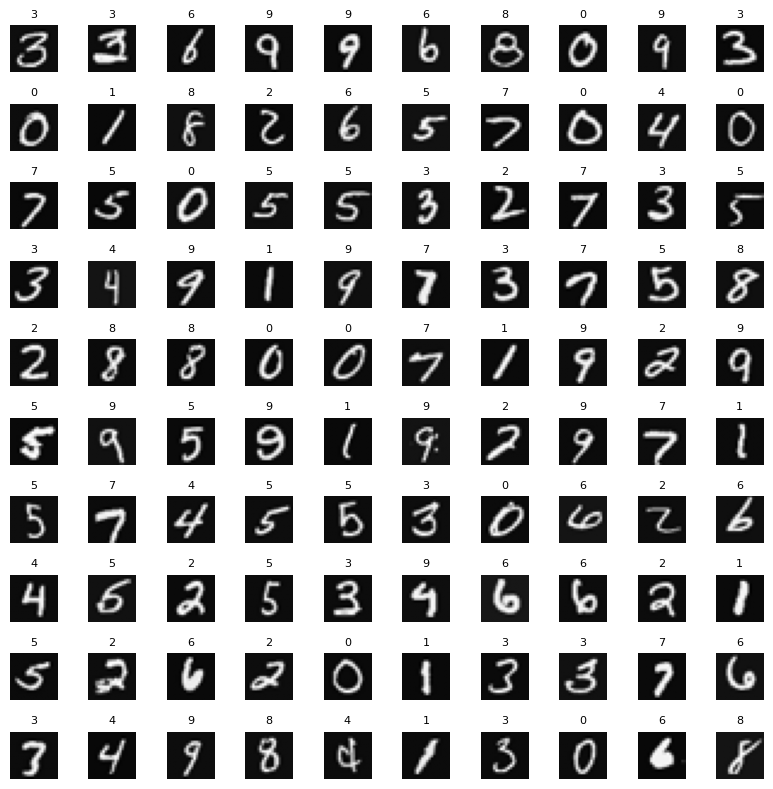

In [ ]:
def display_random_images(X, y):
    indices = np.random.choice(X.shape[0], 100, replace=False)
    images = X[indices, :].reshape(-1, 20, 20).transpose(0, 2, 1)
    labels = y[indices]

    fig, axes = plt.subplots(10, 10, figsize=(8, 8))
    for i, ax in enumerate(axes.flat):
        ax.imshow(images[i], cmap='gray')
        ax.set_title(f"{labels[i]}", fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
display_random_images(X, y)


## Treinamento

In [ ]:
# Dividir em treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Treinar SVM com kernel RBF
clf = svm.SVC(kernel='rbf', C=10, gamma=0.001)
clf.fit(X_train, y_train)

# Avaliar
y_pred = clf.predict(X_test)
print("Acurácia:", metrics.accuracy_score(y_test, y_pred))

Acurácia: 0.927


## Descobrindo os melhores parâmetros

In [ ]:
from sklearn.model_selection import GridSearchCV
parameters = {'C': [0.1, 1, 10], 'gamma': [0.001, 0.01, 0.1]}
grid_search = GridSearchCV(svm.SVC(kernel='rbf'), parameters, cv=5)
grid_search.fit(X_train, y_train)
print("Melhores parâmetros:", grid_search.best_params_)

Melhores parâmetros: {'C': 10, 'gamma': 0.1}


In [ ]:
from sklearn import datasets, svm, metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# Treinar SVM com kernel RBF
clf = svm.SVC(kernel='rbf', C=10, gamma=0.1)
clf.fit(X_train, y_train)

# Avaliar
y_pred = clf.predict(X_test)
print("Acurácia:", metrics.accuracy_score(y_test, y_pred))

Acurácia: 0.962


# SVM não-linear

O código abaixo é uma implementação de classificador para MNIST que utiliza o Histogram of Oriented Gradients (HOG) -- um método para extrair características de imagens.

O HOG  analisa padrões locais de gradientes, capturando a estrutura  dos objetos. No caso do MNIST, esse método extrai características das curvas, linhas e ângulos dos dígitos.

Ao transformar as imagens em vetores HOG, criamos um espaço de características onde a SVM com RBF pode encontrar os melhores limites de decisão entre as diferentes classes numéricas.

In [ ]:
import numpy as np
from sklearn import svm
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score
from skimage.feature import hog
import time


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Extração HOG com parâmetros conservadores
def extract_hog_features(images):
    features = []
    for img in images:
        img_20x20 = img.reshape(20, 20)
        fd = hog(img_20x20,
                orientations=8,
                pixels_per_cell=(5,5),
                cells_per_block=(2,2),
                block_norm='L2-Hys',
                feature_vector=True)
        features.append(fd)
    return np.array(features)

print("Extraindo features HOG...")
X_train_hog = extract_hog_features(X_train)
X_test_hog = extract_hog_features(X_test)

# Verificação básica dos dados
print("\nVerificação dos dados:")
print(f"Dimensões HOG treino: {X_train_hog.shape}")
print(f"Valores mínimos/máximos: {X_train_hog.min()}, {X_train_hog.max()}")
print(f"Contém NaN? {np.isnan(X_train_hog).any()}")

# Configuração robusta do SVM RBF
print("\nConfigurando SVM RBF...")

# Primeiro: modelo básico para teste
base_model = svm.SVC(kernel='rbf', C=1, gamma='scale', random_state=42)
print("Testando modelo base...")
base_model.fit(X_train_hog[:1000], y_train[:1000])  # Subset pequeno para teste
base_score = base_model.score(X_test_hog[:100], y_test[:100])
print(f"Acurácia do modelo base: {base_score:.4f}")

# Busca de hiperparâmetros com fallback seguro
param_grid = [
    {'kernel': ['rbf'], 'C': [0.1, 1, 10], 'gamma': ['scale', 'auto', 0.1]},
    {'kernel': ['linear'], 'C': [0.1, 1, 10]}
]

try:
    print("\nIniciando busca de hiperparâmetros...")
    search = GridSearchCV(
        svm.SVC(random_state=42),
        param_grid,
        cv=3,
        n_jobs=-1,
        verbose=2,
        error_score='raise'  # Para ver erros específicos
    )
    search.fit(X_train_hog[:3000], y_train[:3000])  # Usando subset para velocidade

    print("\nMelhores parâmetros:", search.best_params_)
    best_svm = search.best_estimator_

except Exception as e:
    print(f"\nErro durante GridSearch: {str(e)}")
    print("Usando configuração padrão RBF como fallback...")
    best_svm = svm.SVC(kernel='rbf', C=10, gamma='scale', random_state=42)

# Treinamento final
print("\nTreinando modelo final...")
start_time = time.time()
best_svm.fit(X_train_hog, y_train)
print(f"Tempo de treinamento: {time.time() - start_time:.2f}s")

# Avaliação
y_pred = best_svm.predict(X_test_hog)
accuracy = accuracy_score(y_test, y_pred)
print(f"\nAcurácia final: {accuracy:.4f}")

# 8. Análise adicional
print("\nDistribuição das classes preditas:")
print(np.unique(y_pred, return_counts=True))

Extraindo features HOG...

Verificação dos dados:
Dimensões HOG treino: (4000, 288)
Valores mínimos/máximos: 0.0, 0.9973457220735079
Contém NaN? False

Configurando SVM RBF...
Testando modelo base...
Acurácia do modelo base: 0.9800

Iniciando busca de hiperparâmetros...
Fitting 3 folds for each of 12 candidates, totalling 36 fits

Melhores parâmetros: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}

Treinando modelo final...
Tempo de treinamento: 0.76s

Acurácia final: 0.9720

Distribuição das classes preditas:
(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8), array([113, 103, 109,  83,  88,  99,  98, 112,  83, 112]))
